# Caracterización de modelos ejecutados con LocalScore (solo modelos)

Notebook para enriquecer y resumir **métricas por modelo** (familia, tamaño y cuantización) usando el dump de LocalScore, **sin** tipificación de hardware (sin perfiles H1–H6 y sin cruzar con RAM/VRAM).

**Sección explícita — Análisis de cuantización:** está **justo después** de la celda *Enriquecimiento: familia + tamaño* (encabezado *Análisis de cuantización (`model_variant_quant`)*). En el índice/outline del editor, buscá ese título de nivel 2.

Fuentes principales:
- `data/raw/localscore-09-24-2025.db` (SQLite raw)
- (check opcional) `data/processed/localscore_runs_labeled_H1-H6.csv`

In [1]:
%matplotlib inline

import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

try:
    import seaborn as sns
    HAS_SEABORN = True
except Exception:
    HAS_SEABORN = False


# =========================
# Rutas y configuración
# =========================
DB_PATH = Path("../data/raw/localscore-09-24-2025.db")
OUT_DIR = Path("../data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

if not DB_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró la DB raw en: {DB_PATH}." 
        "Verificá que el dump de LocalScore esté en `data/raw/`"
    )

TOP_K = 10

# Orden de bins para plots
SIZE_BIN_ORDER = [
    "LT1B",
    "1-2B",
    "2-4B",
    "4-8B",
    "8-16B",
    "16-32B",
    "32-64B",
    "GE64B",
]


In [2]:
# =========================
# Carga (SQL modelo-only)
# =========================
conn = sqlite3.connect(DB_PATH)

query = """
SELECT
  br.id                           AS benchmark_run_id,
  br.id                           AS run_name,
  br.model_variant_id,
  br.runtime_id,
  br.avg_prompt_tps,
  br.avg_gen_tps,
  br.avg_ttft_ms,
  br.performance_score,
  mv.quantization                AS model_variant_quant,
  m.name                         AS model_name,
  m.params,
  r.name                         AS runtime_name
FROM benchmark_runs br
JOIN model_variants mv
  ON br.model_variant_id = mv.id
JOIN models m
  ON mv.model_id = m.id
JOIN runtimes r
  ON br.runtime_id = r.id
"""

df = pd.read_sql_query(query, conn)
print("runs shape:", df.shape)
print("columns:", list(df.columns))
df.head(2)

runs shape: (1556, 12)
columns: ['benchmark_run_id', 'run_name', 'model_variant_id', 'runtime_id', 'avg_prompt_tps', 'avg_gen_tps', 'avg_ttft_ms', 'performance_score', 'model_variant_quant', 'model_name', 'params', 'runtime_name']


,benchmark_run_id,run_name,model_variant_id,runtime_id,avg_prompt_tps,avg_gen_tps,avg_ttft_ms,performance_score,model_variant_quant,model_name,params,runtime_name
0,1,1,1,1,3552.260062,103.101197,357.877564,1007.731103,Q4_K - Medium,Meta Llama 3.1 8B Instruct,8030263296,llamafile
1,2,2,2,1,2005.328495,59.943200,640.390159,572.567815,Q4_K - Medium,Qwen2.5 14B Instruct,14770033664,llamafile


In [3]:
# =====================================
# Normalización de tipos numéricos
# =====================================
NUM_COLS = [
    "avg_prompt_tps",
    "avg_gen_tps",
    "avg_ttft_ms",
    "performance_score",
    "params",
]

for c in NUM_COLS:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors="coerce")

# Sanitizar claves
for c in ["model_name", "model_variant_quant", "runtime_name"]:
    if c in df.columns:
        df[c] = df[c].fillna("UNKNOWN").astype(str)

# Validación mínima
missing = df[NUM_COLS].isna().mean().sort_values(ascending=False)
print("NaN rate por columna (top):")
print(missing.head(10))

df[["model_name", "model_variant_quant", "runtime_name", "params", "avg_gen_tps", "avg_ttft_ms" ]].head(3)

NaN rate por columna (top):
avg_prompt_tps       0.0
avg_gen_tps          0.0
avg_ttft_ms          0.0
performance_score    0.0
params               0.0
dtype: float64


,model_name,model_variant_quant,runtime_name,params,avg_gen_tps,avg_ttft_ms
0,Meta Llama 3.1 8B Instruct,Q4_K - Medium,llamafile,8030263296,103.101197,357.877564
1,Qwen2.5 14B Instruct,Q4_K - Medium,llamafile,14770033664,59.943200,640.390159
2,Llama 3.2 1B Instruct,Q4_K - Medium,llamafile,1498483200,330.012790,94.525489


In [4]:
# =====================================
# Enriquecimiento: familia + tamaño
# =====================================
# Heurística simple basada en keywords del nombre (reutilizada de tu notebook)
FAMILY_KEYWORDS = {
    "Llama": ["LLAMA"],
    "Qwen": ["QWEN"],
    "Gemma": ["GEMMA"],
    "Mistral": ["MISTRAL", "NEMO"],
    "DeepSeek": ["DEEPSEEK"],
    "Phi": ["PHI"],
    "Ministral": ["MINISTRAL"],
    "ExaOne": ["EXAONE"],
}

def infer_family(model_name: str) -> str:
    if model_name is None or pd.isna(model_name):
        return "UNKNOWN"
    name = str(model_name).upper()
    for fam, kws in FAMILY_KEYWORDS.items():
        if any(kw in name for kw in kws):
            return fam
    return "OTHER"

df["model_family"] = df["model_name"].apply(infer_family)

# Bins log2 basados en params (conteo absoluto de parámetros)
B1 = 1e9
B2 = 2e9
B3 = 4e9
B4 = 8e9
B5 = 16e9
B6 = 32e9
B7 = 64e9

def size_bin_params(p):
    if p is None or pd.isna(p):
        return "UNKNOWN"
    p = float(p)
    if p < B1:
        return "LT1B"
    if p < B2:
        return "1-2B"
    if p < B3:
        return "2-4B"
    if p < B4:
        return "4-8B"
    if p < B5:
        return "8-16B"
    if p < B6:
        return "16-32B"
    if p < B7:
        return "32-64B"
    return "GE64B"

df["size_bin_params"] = df["params"].apply(size_bin_params)
df["size_bin_params"] = pd.Categorical(df["size_bin_params"], categories=SIZE_BIN_ORDER, ordered=True)

print("Familias:")
print(df["model_family"].value_counts().head(30))

print("Bins tamaño:")
print(df["size_bin_params"].value_counts(dropna=False).sort_index())

df[["model_name","model_family","params","size_bin_params","model_variant_quant","runtime_name"]].head(5)

Familias:
Llama        1015
Qwen          401
Gemma          65
OTHER          40
Mistral        21
Phi            11
Ministral       2
ExaOne          1
Name: model_family, dtype: int64
Bins tamaño:
LT1B       27
1-2B      702
2-4B       47
4-8B       57
8-16B     695
16-32B     22
32-64B      5
GE64B       1
Name: size_bin_params, dtype: int64


,model_name,model_family,params,size_bin_params,model_variant_quant,runtime_name
0,Meta Llama 3.1 8B Instruct,Llama,8030263296,8-16B,Q4_K - Medium,llamafile
1,Qwen2.5 14B Instruct,Qwen,14770033664,8-16B,Q4_K - Medium,llamafile
2,Llama 3.2 1B Instruct,Llama,1498483200,1-2B,Q4_K - Medium,llamafile
3,Llama 3.2 1B Instruct,Llama,1498483200,1-2B,Q4_K - Medium,llamafile
4,Llama 3.2 1B Instruct,Llama,1498483200,1-2B,Q4_K - Medium,llamafile


## Análisis de cuantización (`model_variant_quant`)

**Dónde va en el flujo:** inmediatamente **después** de crear `model_family` y `size_bin_params` (celda anterior: *Enriquecimiento: familia + tamaño*).

Objetivo: ver **cuántas etiquetas distintas** hay en la muestra, si una o pocas **dominan** (y entonces un análisis fino H×M×quant aporta poco), y si hay **masa suficiente** por bin de tamaño para contrastar cuantizaciones. Complementa la discusión de perfiles de modelo basados solo en parámetros.

In [5]:
# =====================================
# Análisis de cuantización (model_variant_quant)
# =====================================
# Dominancia global, cruce con size_bin_params, agrupación gruesa y medianas
# donde n sea razonable (sin añadir columnas permanentes a df).

vc = df["model_variant_quant"].value_counts(dropna=False)
n_total = len(df)
print(f"Total corridas: {n_total}")
print(f"Etiquetas distintas (model_variant_quant): {vc.size}\n")

vc_pct = (vc / n_total * 100).round(2)
summary = pd.DataFrame({"n": vc, "pct": vc_pct, "pct_acum": vc_pct.cumsum().round(2)})
print("Distribución (orden decreciente, top 25):")
print(summary.head(25).to_string())

top1_share = vc.iloc[0] / n_total
top3_share = vc.head(3).sum() / n_total
print(f"\nShare top-1 cuantización: {100 * top1_share:.1f}%")
print(f"Share top-3 cuantizaciones: {100 * top3_share:.1f}%")

na_n = df["model_variant_quant"].isna().sum()
print(f"NaN en model_variant_quant: {na_n} ({100 * na_n / n_total:.2f}%)\n")

# Cruce size_bin × quant: solo columnas con masa global suficiente
ct = pd.crosstab(df["size_bin_params"], df["model_variant_quant"], dropna=False)
col_totals = ct.sum(axis=0).sort_values(ascending=False)
min_n_col = max(20, int(0.01 * n_total))
cols_keep = col_totals[col_totals >= min_n_col].index.tolist()
print(f"Cruce size_bin × quant: shape {ct.shape}")
print(
    f"Columnas con n_col >= {min_n_col} (~1% del total o mín. 20 corridas en esa cuantización): {len(cols_keep)}"
)
if cols_keep:
    print(ct[cols_keep].to_string())
else:
    print("(ninguna columna supera el umbral; la muestra está muy fragmentada por cuantización)")


def coarse_quant(s):
    if pd.isna(s):
        return "NA"
    u = str(s).upper()
    if u.startswith("Q4"):
        return "Q4*"
    if u.startswith("Q3"):
        return "Q3*"
    if u.startswith("Q5") or u.startswith("Q6"):
        return "Q5-Q6*"
    if u.startswith("Q8") or u.startswith("Q2"):
        return "Q2/Q8*"
    if "F16" in u or "BF16" in u or "F32" in u:
        return "FP/BF/F32"
    if u.startswith("IQ"):
        return "IQ*"
    return "otros"


quant_coarse = df["model_variant_quant"].apply(coarse_quant)
vc_coarse = quant_coarse.value_counts()
print("\nAgrupación gruesa (heurística por prefijo), % del total:")
print((vc_coarse / n_total * 100).round(2).to_string())

# Medianas avg_gen_tps por etiqueta original, solo si n >= 30
rows = []
for q, sub in df.groupby("model_variant_quant", dropna=False):
    x = sub["avg_gen_tps"]
    nq = int(x.count())
    if nq < 30:
        continue
    rows.append(
        {
            "model_variant_quant": q,
            "n": nq,
            "median_gen_tps": float(x.median()),
            "p25_gen_tps": float(x.quantile(0.25)),
            "p75_gen_tps": float(x.quantile(0.75)),
        }
    )
med_by_q = pd.DataFrame(rows).sort_values("n", ascending=False)
print(f"\nCuantizaciones con n>=30: medianas de avg_gen_tps (todas las que califiquen, orden por n):")
if med_by_q.empty:
    print("(ninguna etiqueta alcanza n>=30)")
else:
    print(med_by_q.to_string(index=False))

Total corridas: 1556
Etiquetas distintas (model_variant_quant): 15

Distribución (orden decreciente, top 25):
                    n    pct  pct_acum
Q4_K - Medium    1332  85.60     85.60
Q8_0               70   4.50     90.10
Q6_K               40   2.57     92.67
Q4_0               31   1.99     94.66
Q5_K - Medium      29   1.86     96.52
F16                17   1.09     97.61
BF16               11   0.71     98.32
Q2_K - Medium       8   0.51     98.83
Q4_K - Small        5   0.32     99.15
Q3_K - Large        5   0.32     99.47
Q3_K - Medium       4   0.26     99.73
IQ2_M - 2.7 bpw     1   0.06     99.79
Q5_K - Small        1   0.06     99.85
all F32             1   0.06     99.91
Q3_K - Small        1   0.06     99.97

Share top-1 cuantización: 85.6%
Share top-3 cuantizaciones: 92.7%
NaN en model_variant_quant: 0 (0.00%)

Cruce size_bin × quant: shape (8, 15)
Columnas con n_col >= 20 (~1% del total o mín. 20 corridas en esa cuantización): 5
model_variant_quant  Q4_K - Medium  Q8_

In [6]:
# =====================================
# Agregaciones: tabla por modelo
# =====================================
def q25(x: pd.Series) -> float:
    return float(x.quantile(0.25))

def q75(x: pd.Series) -> float:
    return float(x.quantile(0.75))

# Nivel 1: por modelo (sin cuantización)
table_model = (
    df.groupby(["model_family", "size_bin_params", "model_name", "runtime_name"], dropna=False)
      .agg(
          n_runs=("benchmark_run_id", "count"),
          ttft_ms_median=("avg_ttft_ms", "median"),
          ttft_ms_p25=("avg_ttft_ms", q25),
          ttft_ms_p75=("avg_ttft_ms", q75),
          gen_tps_median=("avg_gen_tps", "median"),
          gen_tps_p25=("avg_gen_tps", q25),
          gen_tps_p75=("avg_gen_tps", q75),
          score_median=("performance_score", "median"),
          score_p25=("performance_score", q25),
          score_p75=("performance_score", q75),
          score_mean=("performance_score", "mean"),
      )
      .reset_index()
)

# Orden útil: throughput alto, luego TTFT bajo
table_model = table_model.sort_values(
    by=["model_family","size_bin_params","gen_tps_median","ttft_ms_median"],
    ascending=[True, True, False, True],
)

table_model.head(20)

,model_family,size_bin_params,model_name,runtime_name,n_runs,ttft_ms_median,ttft_ms_p25,ttft_ms_p75,gen_tps_median,gen_tps_p25,gen_tps_p75,score_median,score_p25,score_p75,score_mean
0,ExaOne,LT1B,.,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ExaOne,LT1B,..,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ExaOne,LT1B,AMD OLMo 1B,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ExaOne,LT1B,AReaL Boba RL 7B,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ExaOne,LT1B,Amoral Gemma3 12B,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,ExaOne,LT1B,Arch Agent 7B,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,ExaOne,LT1B,C:\LLM_MODELS\mistralai,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,ExaOne,LT1B,Cogito v1 Preview Llama 8B,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,ExaOne,LT1B,Cogito v1 Preview Qwen 14B,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,ExaOne,LT1B,DeepSeek R1 Distill Llama 8B,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# =====================================
# Agregaciones: tabla por configuración atómica (modelo+cuant)
# =====================================
table_config = (
    df.groupby(
        ["model_family", "size_bin_params", "model_name", "model_variant_quant", "runtime_name"],
        dropna=False,
    )
      .agg(
          n_runs=("benchmark_run_id", "count"),
          ttft_ms_median=("avg_ttft_ms", "median"),
          ttft_ms_p25=("avg_ttft_ms", q25),
          ttft_ms_p75=("avg_ttft_ms", q75),
          gen_tps_median=("avg_gen_tps", "median"),
          gen_tps_p25=("avg_gen_tps", q25),
          gen_tps_p75=("avg_gen_tps", q75),
          score_median=("performance_score", "median"),
          score_p25=("performance_score", q25),
          score_p75=("performance_score", q75),
          score_mean=("performance_score", "mean"),
      )
      .reset_index()
)

table_config = table_config.sort_values(
    by=["model_family","size_bin_params","runtime_name","gen_tps_median","ttft_ms_median","score_median"],
    ascending=[True, True, True, False, True, False],
)

table_config.head(20)

,model_family,size_bin_params,model_name,model_variant_quant,runtime_name,n_runs,ttft_ms_median,ttft_ms_p25,ttft_ms_p75,gen_tps_median,gen_tps_p25,gen_tps_p75,score_median,score_p25,score_p75,score_mean
0,ExaOne,LT1B,.,BF16,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ExaOne,LT1B,.,F16,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ExaOne,LT1B,.,IQ2_M - 2.7 bpw,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ExaOne,LT1B,.,Q2_K - Medium,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ExaOne,LT1B,.,Q3_K - Large,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,ExaOne,LT1B,.,Q3_K - Medium,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,ExaOne,LT1B,.,Q3_K - Small,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,ExaOne,LT1B,.,Q4_0,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,ExaOne,LT1B,.,Q4_K - Medium,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,ExaOne,LT1B,.,Q4_K - Small,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# =====================================
# Ranking top-k (unico, descriptivo)
# =====================================
# Grupos: (familia, bin tamaño, runtime)
rank_df = table_config.copy()

rank_df = rank_df.sort_values(
    by=["model_family","size_bin_params","runtime_name","gen_tps_median","ttft_ms_median","score_median"],
    ascending=[True, True, True, False, True, False],
)

# rank dentro de cada grupo
rank_df["rank"] = (
    rank_df.groupby(["model_family","size_bin_params","runtime_name"], dropna=False)
           .cumcount() + 1
)

ranking_topk = rank_df[rank_df["rank"] <= TOP_K].copy()

ranking_topk.head(30)

,model_family,size_bin_params,model_name,model_variant_quant,runtime_name,n_runs,ttft_ms_median,ttft_ms_p25,ttft_ms_p75,gen_tps_median,gen_tps_p25,gen_tps_p75,score_median,score_p25,score_p75,score_mean,rank
0,ExaOne,LT1B,.,BF16,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,ExaOne,LT1B,.,F16,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
2,ExaOne,LT1B,.,IQ2_M - 2.7 bpw,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3
3,ExaOne,LT1B,.,Q2_K - Medium,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4
4,ExaOne,LT1B,.,Q3_K - Large,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5
5,ExaOne,LT1B,.,Q3_K - Medium,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6
6,ExaOne,LT1B,.,Q3_K - Small,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7
7,ExaOne,LT1B,.,Q4_0,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8
8,ExaOne,LT1B,.,Q4_K - Medium,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9
9,ExaOne,LT1B,.,Q4_K - Small,llamafile,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10


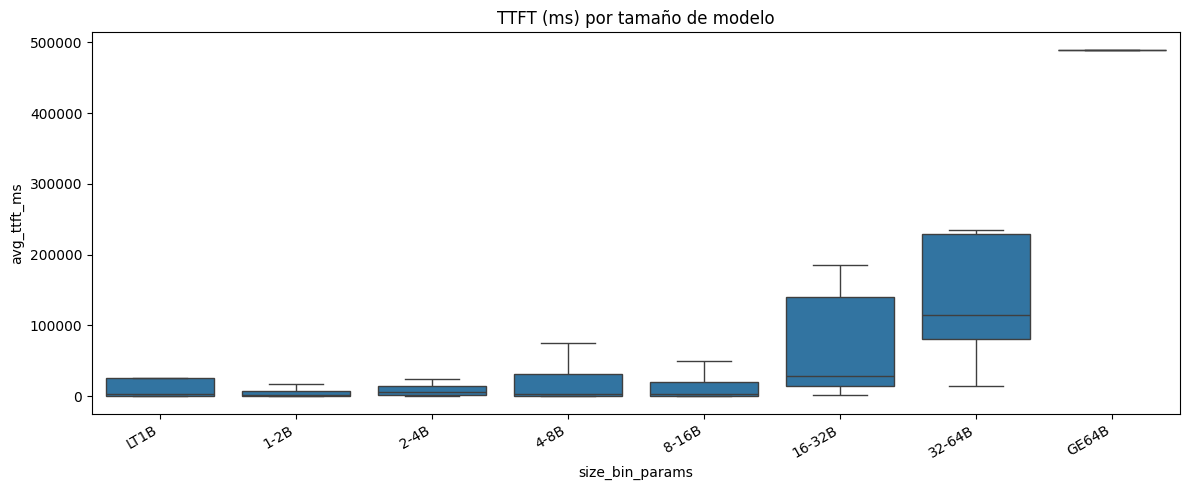

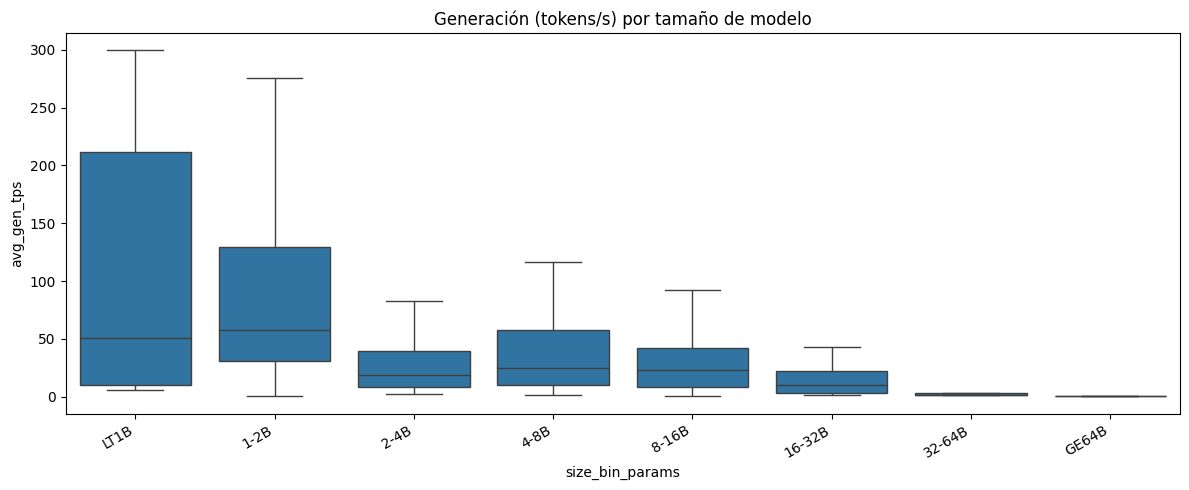

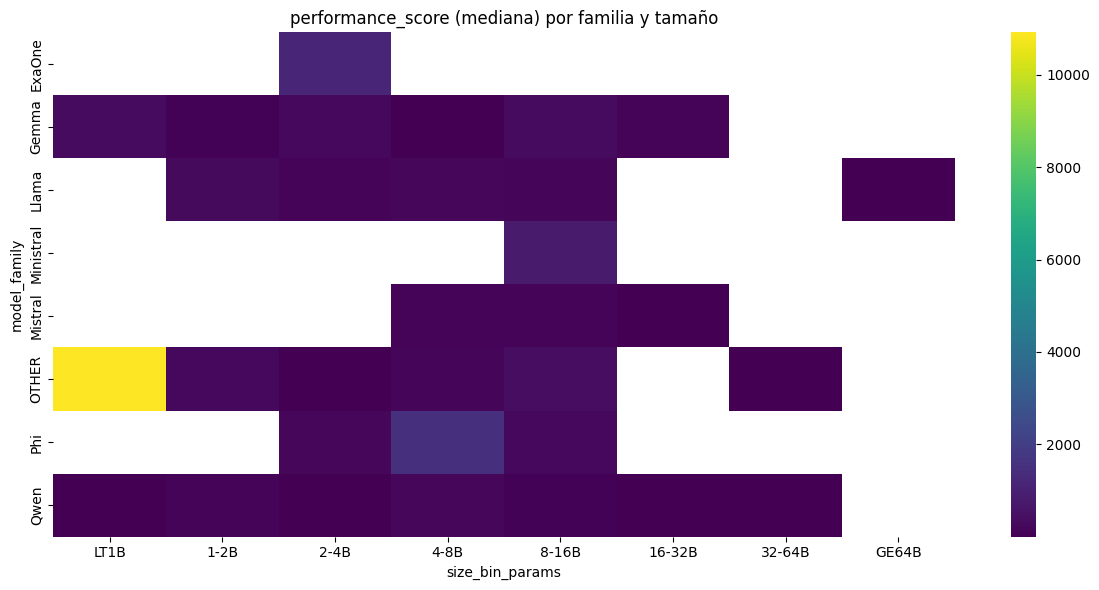

In [9]:
# =====================================
# Plots diagnósticos (sin hardware)
# =====================================

plt.figure(figsize=(12,5))
if HAS_SEABORN:
    sns.boxplot(data=df, x="size_bin_params", y="avg_ttft_ms", showfliers=False)
else:
    df.boxplot(column="avg_ttft_ms", by="size_bin_params", grid=False, showfliers=False)
    plt.suptitle("")
plt.title("TTFT (ms) por tamaño de modelo")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,5))
if HAS_SEABORN:
    sns.boxplot(data=df, x="size_bin_params", y="avg_gen_tps", showfliers=False)
else:
    df.boxplot(column="avg_gen_tps", by="size_bin_params", grid=False, showfliers=False)
    plt.suptitle("")
plt.title("Generación (tokens/s) por tamaño de modelo")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Heatmap: score_median por familia y size_bin
pivot = (
    table_config.groupby(["model_family","size_bin_params"])["score_median"]
                .median()
                .reset_index()
)

heat = pivot.pivot(index="model_family", columns="size_bin_params", values="score_median")
heat = heat.reindex(columns=SIZE_BIN_ORDER)

plt.figure(figsize=(12,6))
if HAS_SEABORN:
    sns.heatmap(heat, annot=False, cmap="viridis")
else:
    plt.imshow(heat.values, aspect="auto", interpolation="nearest")
    plt.colorbar(label="score_median")
    plt.xticks(range(len(heat.columns)), heat.columns, rotation=30, ha="right")
    plt.yticks(range(len(heat.index)), heat.index)
plt.title("performance_score (mediana) por familia y tamaño")
plt.tight_layout()
plt.show()

In [10]:
# =====================================
# Export (CSV + Parquet condicional)
# =====================================
run_out = df.copy()

csv_runs_path = OUT_DIR / "localscore_models_solo_runs_enriched.csv"
run_out.to_csv(csv_runs_path, index=False)
print("Export run-level CSV:", csv_runs_path)

parquet_runs_path = OUT_DIR / "localscore_models_solo_runs_enriched.parquet"
try:
    run_out.to_parquet(parquet_runs_path, index=False)
    print("Export run-level Parquet:", parquet_runs_path)
except Exception as e:
    print("No se pudo exportar Parquet de runs.")
    print("Error:", e)

csv_table_model_path = OUT_DIR / "localscore_models_solo_table_by_model.csv"
table_model.to_csv(csv_table_model_path, index=False)
print("Export table_model CSV:", csv_table_model_path)

csv_table_config_path = OUT_DIR / "localscore_models_solo_table_by_model_quant.csv"
table_config.to_csv(csv_table_config_path, index=False)
print("Export table_config CSV:", csv_table_config_path)

ranking_path = OUT_DIR / "localscore_models_solo_ranking_topk_by_family_size_runtime.csv"
ranking_topk.to_csv(ranking_path, index=False)
print("Export ranking:", ranking_path)


Export run-level CSV: ../data/processed/localscore_models_solo_runs_enriched.csv
No se pudo exportar Parquet de runs.
Error: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Export table_model CSV: ../data/processed/localscore_models_solo_table_by_model.csv


Export table_config CSV: ../data/processed/localscore_models_solo_table_by_model_quant.csv
Export ranking: ../data/processed/localscore_models_solo_ranking_topk_by_family_size_runtime.csv


In [11]:
# =====================================
# Consistencia: check contra notebook anterior (sin tipificar hardware)
# =====================================
# Idea: si el SQL es consistente, deberían coincidir las agregaciones por
# (model_name, model_variant_quant, runtime_name) en términos de medianas
# de gen_tps/ttft.

EXISTING_H1H6_PATH = Path("../data/processed/localscore_runs_labeled_H1-H6.csv")

if EXISTING_H1H6_PATH.exists():
    df_old = pd.read_csv(EXISTING_H1H6_PATH)

    # Estandarizar
    if "quantization" in df_old.columns and "model_variant_quant" not in df_old.columns:
        df_old["model_variant_quant"] = df_old["quantization"]

    for c in ["avg_gen_tps","avg_ttft_ms","performance_score","params"]:
        if c in df_old.columns:
            df_old[c] = pd.to_numeric(df_old[c], errors="coerce")

    # inferir familia y tamaño para poder agrupar igual
    df_old["model_family"] = df_old["model_name"].apply(infer_family)
    df_old["size_bin_params"] = df_old["params"].apply(size_bin_params)
    df_old["size_bin_params"] = pd.Categorical(df_old["size_bin_params"], categories=SIZE_BIN_ORDER, ordered=True)

    old_agg = (
        df_old.groupby(["model_family","size_bin_params","model_name","model_variant_quant","runtime_name"], dropna=False)
              .agg(
                  gen_tps_median_old=("avg_gen_tps","median"),
                  ttft_ms_median_old=("avg_ttft_ms","median"),
                  score_mean_old=("performance_score","mean"),
              )
              .reset_index()
    )

    # Nuestro agregador (usar tabla_config)
    new_agg = table_config[[
        "model_family","size_bin_params","model_name","model_variant_quant","runtime_name",
        "gen_tps_median","ttft_ms_median","score_mean"
    ]].rename(columns={
        "gen_tps_median":"gen_tps_median_new",
        "ttft_ms_median":"ttft_ms_median_new",
        "score_mean":"score_mean_new",
    })

    merged = old_agg.merge(new_agg, on=[
        "model_family","size_bin_params","model_name","model_variant_quant","runtime_name"
    ], how="inner")

    if len(merged) == 0:
        print("Check inconsistente: no hay claves para mergear (0 filas).")
    else:
        merged["abs_diff_gen_tps"] = (merged["gen_tps_median_new"] - merged["gen_tps_median_old"]).abs()
        merged["abs_diff_ttft_ms"] = (merged["ttft_ms_median_new"] - merged["ttft_ms_median_old"]).abs()
        merged["abs_diff_score_mean"] = (merged["score_mean_new"] - merged["score_mean_old"]).abs()

        print("Check merge filas:", len(merged))
        print("Abs diff gen_tps_median (media):", merged["abs_diff_gen_tps"].mean())
        print("Abs diff ttft_ms_median (media):", merged["abs_diff_ttft_ms"].mean())
        print("Abs diff score_mean (media):", merged["abs_diff_score_mean"].mean())
        print("Abs diff gen_tps_median (max):", merged["abs_diff_gen_tps"].max())
        print("Abs diff ttft_ms_median (max):", merged["abs_diff_ttft_ms"].max())
        print("Abs diff score_mean (max):", merged["abs_diff_score_mean"].max())

else:
    print("No se encontró el CSV existente para el check.")
    print("Esperado:", EXISTING_H1H6_PATH)


Check merge filas: 114240
Abs diff gen_tps_median (media): 4.65422907185997e-15
Abs diff ttft_ms_median (media): 2.0856519126134705e-13
Abs diff score_mean (media): 3.2218236793043757e-16
Abs diff gen_tps_median (max): 9.094947017729282e-13
Abs diff ttft_ms_median (max): 2.9103830456733704e-11
Abs diff score_mean (max): 2.842170943040401e-14


Modelos tras limpiar+canonicalizar: 98


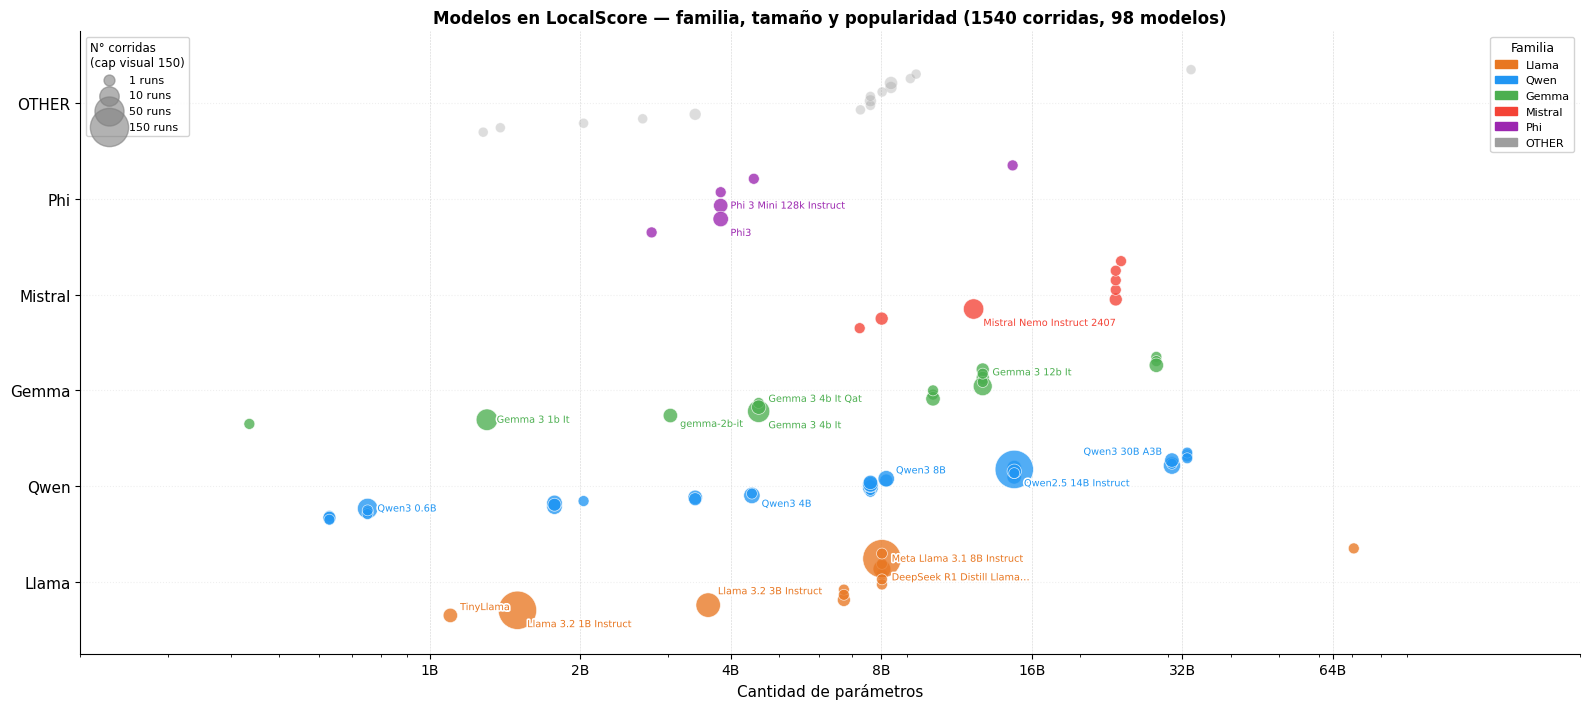

Guardado: ../reports/figures/fig02a_models_bubble_family.png


In [12]:
# =====================================
# Fig 02a — Bubble chart: familia × params × popularidad (v4)
# =====================================
from matplotlib.patches import Patch
from matplotlib import patheffects as pe
import re

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

FAMILY_COLORS = {
    "Llama":     "#E87722",
    "Qwen":      "#2196F3",
    "Gemma":     "#4CAF50",
    "Mistral":   "#F44336",
    "Phi":       "#9C27B0",
    "ExaOne":    "#795548",
    "OTHER":     "#9E9E9E",
}
FAMILY_ORDER = ["Llama", "Qwen", "Gemma", "Mistral", "Phi", "OTHER"]

GARBAGE_NAMES = {
    ".", "..", "active", "hub", "Models", "Dir", "Model Hf", "Local_Pretrained_Model",
}

def canonical_name(name: str) -> str:
    n = str(name).strip()
    if n in GARBAGE_NAMES:
        return n
    alias_map = {
        "Llama-3.2-1B-Instruct": "Llama 3.2 1B Instruct",
        "Gemma-3-1B-It": "Gemma 3 1b It",
        "Gemma-3-4B-It": "Gemma 3 4b It",
        "Gemma-3-4B-It-Qat": "Gemma 3 4b It Qat",
        "Gemma-3-12B-It": "Gemma 3 12b It",
        "qwen2.5-1.5b-instruct": "Qwen2.5 1.5B Instruct",
        "qwen2.5-3b-instruct": "Qwen2.5 3B Instruct",
        "qwen2.5-14b-instruct": "Qwen2.5 14B Instruct",
        "Qwen3-0.6B": "Qwen3 0.6B",
        "Qwen3-4B": "Qwen3 4B",
        "Qwen3-30B-A3B": "Qwen3 30B A3B",
        "tinyllama_tinyllama-1.1b-chat-v1.0": "TinyLlama",
    }
    if n in alias_map:
        return alias_map[n]
    return re.sub(r"\s+", " ", n)

FAMILY_KEYWORDS_V2 = {
    "Llama":     ["LLAMA"],
    "Qwen":      ["QWEN", "QWQ"],
    "Gemma":     ["GEMMA"],
    "Mistral":   ["MISTRAL", "MINISTRAL"],
    "Phi":       ["PHI"],
}

def infer_family_v2(name):
    n = str(name).upper()
    for fam, kws in FAMILY_KEYWORDS_V2.items():
        if any(kw in n for kw in kws):
            return fam
    return "OTHER"

def abbrev_name(name, max_len=26):
    if len(name) <= max_len:
        return name
    for suffix in [" Instruct", "-Instruct", " instruct"]:
        name = name.replace(suffix, "")
    return name if len(name) <= max_len else name[:max_len-1] + "…"

# Canonicalización y agregación
df_plot = df.copy()
df_plot["model_name_canon"] = df_plot["model_name"].apply(canonical_name)
df_plot["model_family_v2"] = df_plot["model_name_canon"].apply(infer_family_v2)

models_agg = (
    df_plot.groupby("model_name_canon")
      .agg(
          n_runs       = ("benchmark_run_id", "count"),
          model_family = ("model_family_v2", "first"),
          params       = ("params", "median"),
      )
      .reset_index()
      .rename(columns={"model_name_canon": "model_name"})
)

models_agg = models_agg[~models_agg["model_name"].isin(GARBAGE_NAMES)]
models_agg = models_agg[~models_agg["model_name"].str.contains(r'(?i)[\\/]LLM_MODELS|^[a-zA-Z]{1,2}$', regex=True, na=False)]
models_agg["model_family"] = models_agg["model_family"].apply(lambda x: x if x in FAMILY_COLORS else "OTHER")

print(f"Modelos tras limpiar+canonicalizar: {len(models_agg)}")

family_y = {fam: i for i, fam in enumerate(FAMILY_ORDER)}
models_agg["y_pos"] = 0.0
np.random.seed(42)
for fam in FAMILY_ORDER:
    mask = models_agg["model_family"] == fam
    sorted_idx = models_agg.loc[mask].sort_values("params").index
    n = len(sorted_idx)
    if n == 0:
        continue
    jitter = np.linspace(-0.35, 0.35, n) if n > 1 else [0.0]
    for j, idx in enumerate(sorted_idx):
        models_agg.at[idx, "y_pos"] = family_y[fam] + jitter[j]

# Etiquetas: top5 por familia (min 3 runs, excluye OTHER)
label_df = (
    models_agg[(models_agg["n_runs"] >= 3) & (models_agg["model_family"] != "OTHER")]
      .sort_values(["model_family", "n_runs", "params"], ascending=[True, False, True])
      .groupby("model_family")
      .head(5)
      .copy()
)

# Offsets escalonados por familia para reducir colisiones
label_df["label_rank_fam"] = label_df.groupby("model_family").cumcount()
label_offsets = [-10, 0, 10, -6, 6]

BUBBLE_SCALE = 62
CAP_RUNS = 150
models_agg["bubble_size"] = np.sqrt(np.minimum(models_agg["n_runs"], CAP_RUNS)) * BUBBLE_SCALE

fig, ax = plt.subplots(figsize=(16, 7.2))

for fam in FAMILY_ORDER:
    subset = models_agg[models_agg["model_family"] == fam].copy()
    if subset.empty:
        continue
    alpha = 0.35 if fam == "OTHER" else 0.78
    if fam == "OTHER":
        subset["bubble_size"] = subset["bubble_size"] * 0.8

    ax.scatter(
        subset["params"], subset["y_pos"],
        s=subset["bubble_size"], color=FAMILY_COLORS[fam],
        alpha=alpha, edgecolors="white", linewidths=0.5, zorder=3,
    )

for _, row in label_df.iterrows():
    label = abbrev_name(row["model_name"])
    near_right = row["params"] > 3e10
    dy = label_offsets[int(row["label_rank_fam"]) % len(label_offsets)]
    txt = ax.annotate(
        label,
        xy=(row["params"], row["y_pos"]),
        xytext=((-7, dy) if near_right else (7, dy)),
        textcoords="offset points",
        fontsize=7,
        va="center",
        ha="right" if near_right else "left",
        color=FAMILY_COLORS.get(row["model_family"], "#444"),
    )
    txt.set_path_effects([pe.withStroke(linewidth=2.4, foreground="white")])

PARAM_TICKS = [1e9, 2e9, 4e9, 8e9, 16e9, 32e9, 64e9]
ax.set_xscale("log")
ax.set_xticks(PARAM_TICKS)
ax.set_xticklabels(["1B", "2B", "4B", "8B", "16B", "32B", "64B"], fontsize=10)
ax.set_xlim(2e8, 2e11)
for tick in PARAM_TICKS:
    ax.axvline(tick, color="gray", linestyle="--", linewidth=0.4, alpha=0.35, zorder=1)

ax.set_yticks(range(len(FAMILY_ORDER)))
ax.set_yticklabels(FAMILY_ORDER, fontsize=11)
ax.set_ylim(-0.75, len(FAMILY_ORDER)-0.25)

size_legend = [
    ax.scatter([], [], s=np.sqrt(min(n, CAP_RUNS))*BUBBLE_SCALE, color="gray", alpha=0.6, label=f"{n} runs")
    for n in [1, 10, 50, 150]
]
leg_size = ax.legend(handles=size_legend, title="N° corridas\n(cap visual 150)",
                     loc="upper left", fontsize=8, title_fontsize=8.5, framealpha=0.85)
ax.add_artist(leg_size)

fam_patches = [Patch(color=FAMILY_COLORS[f], label=f)
               for f in FAMILY_ORDER if not models_agg[models_agg["model_family"]==f].empty]
ax.legend(handles=fam_patches, title="Familia", loc="upper right",
          fontsize=8, title_fontsize=9, framealpha=0.85)

total_valid = int(models_agg["n_runs"].sum())
ax.set_xlabel("Cantidad de parámetros", fontsize=11)
ax.set_title(f"Modelos en LocalScore — familia, tamaño y popularidad ({total_valid} corridas, {len(models_agg)} modelos)",
             fontsize=12, fontweight="bold")
ax.grid(axis="y", linestyle=":", alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
fig_path_a = FIG_DIR / "fig02a_models_bubble_family.png"
plt.savefig(fig_path_a, dpi=150, bbox_inches="tight")
plt.show()
print("Guardado:", fig_path_a)





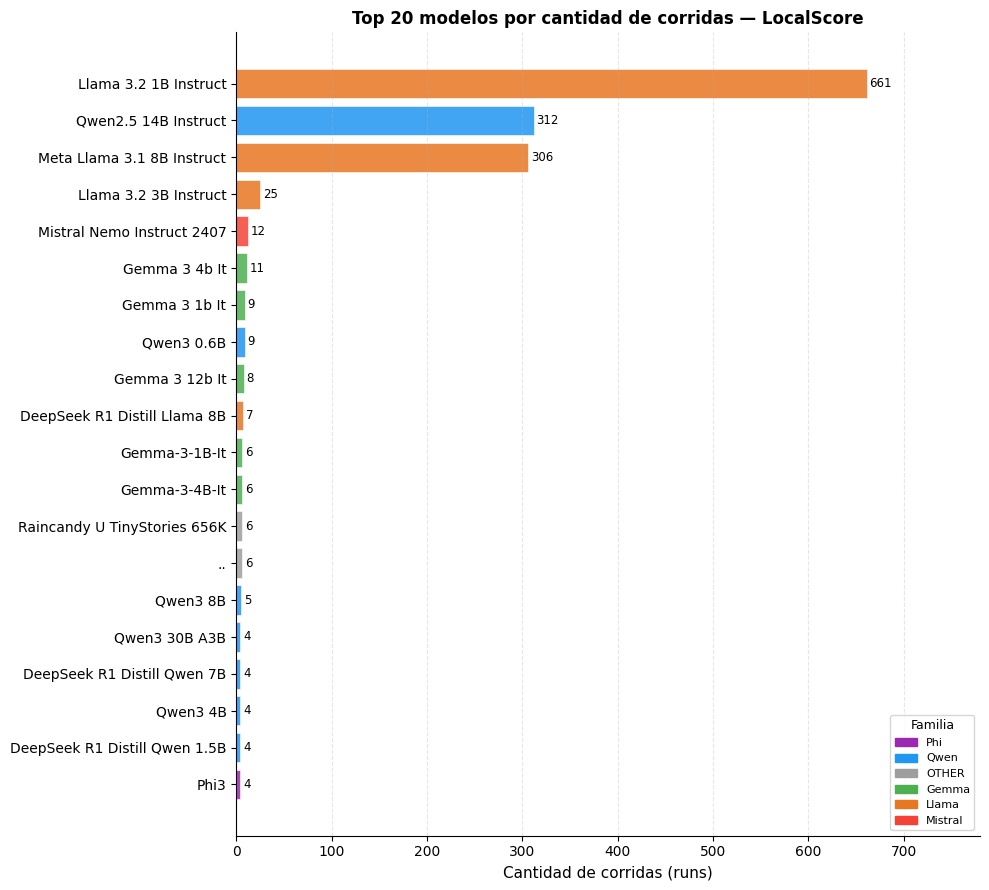

Guardado: ../reports/figures/fig02b_models_top_runs.png


In [13]:
# =====================================
# Fig 02b — Bar chart horizontal: Top 20 modelos por n_runs
# =====================================
top20 = (
    df.groupby("model_name")
      .agg(
          n_runs=("benchmark_run_id", "count"),
          model_family=("model_family", "first"),
      )
      .reset_index()
      .sort_values("n_runs", ascending=False)
      .head(20)
)
top20["model_family"] = top20["model_family"].apply(
    lambda x: x if x in FAMILY_COLORS else "OTHER"
)
top20["label"] = top20["model_name"].apply(lambda x: abbrev_name(x, max_len=32))
top20 = top20.sort_values("n_runs", ascending=True)  # ascendente para barh

fig, ax = plt.subplots(figsize=(10, 9))

bars = ax.barh(
    top20["label"],
    top20["n_runs"],
    color=[FAMILY_COLORS.get(f, "#9E9E9E") for f in top20["model_family"]],
    alpha=0.85,
    edgecolor="white",
    linewidth=0.5,
)

for bar, val in zip(bars, top20["n_runs"]):
    ax.text(
        bar.get_width() + 3,
        bar.get_y() + bar.get_height() / 2,
        str(val),
        va="center",
        ha="left",
        fontsize=8.5,
    )

# Leyenda de familias (solo las que aparecen en el top20)
seen_fams = top20.drop_duplicates("model_family")["model_family"].tolist()
fam_patches = [Patch(color=FAMILY_COLORS.get(f, "#9E9E9E"), label=f) for f in seen_fams]
ax.legend(handles=fam_patches, title="Familia", fontsize=8, title_fontsize=9,
          loc="lower right", framealpha=0.8)

ax.set_xlabel("Cantidad de corridas (runs)", fontsize=11)
ax.set_title("Top 20 modelos por cantidad de corridas — LocalScore",
             fontsize=12, fontweight="bold")
ax.set_xlim(0, top20["n_runs"].max() * 1.18)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
fig_path_b = FIG_DIR / "fig02b_models_top_runs.png"
plt.savefig(fig_path_b, dpi=150, bbox_inches="tight")
plt.show()
print("Guardado:", fig_path_b)

Resumen modelos limpios por familia:
              modelos  runs
model_family               
Gemma              17    65
Llama              14  1015
Mistral             8    21
OTHER              16    26
Phi                 6    11
Qwen               37   402


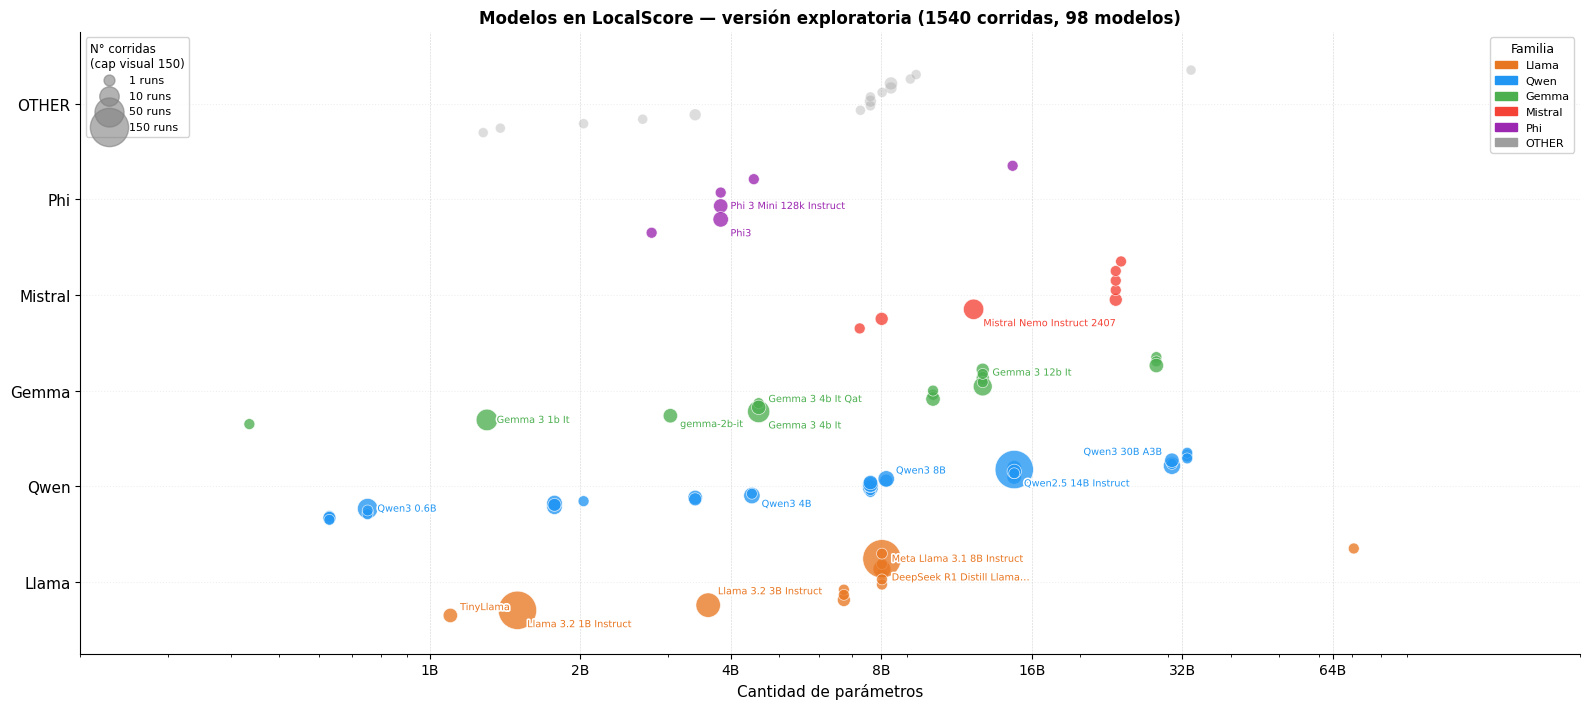

Guardado: ../reports/figures/fig02a_models_bubble_family_exploratory.png


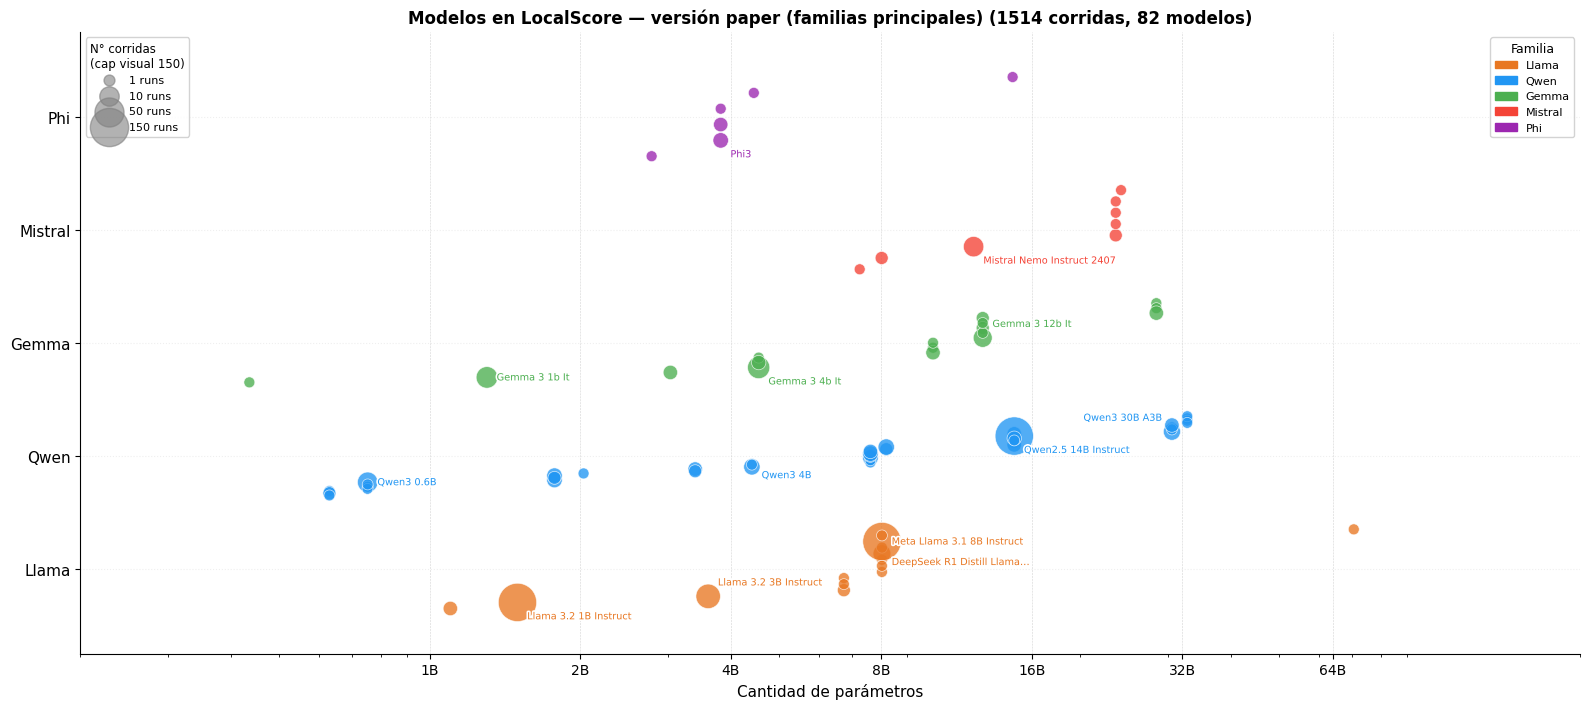

Guardado: ../reports/figures/fig02a_models_bubble_family_paper.png


In [ ]:
# =====================================
# Fig 02a (doble salida): versión exploratoria y versión paper
# =====================================
from matplotlib.patches import Patch
from matplotlib import patheffects as pe
import re

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

FAMILY_COLORS = {
    "Llama":     "#E87722",
    "Qwen":      "#2196F3",
    "Gemma":     "#4CAF50",
    "Mistral":   "#F44336",
    "Phi":       "#9C27B0",
    "ExaOne":    "#795548",
    "OTHER":     "#9E9E9E",
}

GARBAGE_NAMES = {
    ".", "..", "active", "hub", "Models", "Dir", "Model Hf", "Local_Pretrained_Model",
}

def canonical_name(name: str) -> str:
    n = str(name).strip()
    if n in GARBAGE_NAMES:
        return n
    alias_map = {
        "Llama-3.2-1B-Instruct": "Llama 3.2 1B Instruct",
        "Gemma-3-1B-It": "Gemma 3 1b It",
        "Gemma-3-4B-It": "Gemma 3 4b It",
        "Gemma-3-4B-It-Qat": "Gemma 3 4b It Qat",
        "Gemma-3-12B-It": "Gemma 3 12b It",
        "qwen2.5-1.5b-instruct": "Qwen2.5 1.5B Instruct",
        "qwen2.5-3b-instruct": "Qwen2.5 3B Instruct",
        "qwen2.5-14b-instruct": "Qwen2.5 14B Instruct",
        "Qwen3-0.6B": "Qwen3 0.6B",
        "Qwen3-4B": "Qwen3 4B",
        "Qwen3-30B-A3B": "Qwen3 30B A3B",
        "tinyllama_tinyllama-1.1b-chat-v1.0": "TinyLlama",
    }
    if n in alias_map:
        return alias_map[n]
    return re.sub(r"\s+", " ", n)

FAMILY_KEYWORDS_V2 = {
    "Llama":     ["LLAMA"],
    "Qwen":      ["QWEN", "QWQ"],
    "Gemma":     ["GEMMA"],
    "Mistral":   ["MISTRAL", "MINISTRAL"],
    "Phi":       ["PHI"],
}

def infer_family_v2(name):
    n = str(name).upper()
    for fam, kws in FAMILY_KEYWORDS_V2.items():
        if any(kw in n for kw in kws):
            return fam
    return "OTHER"

def abbrev_name(name, max_len=26):
    if len(name) <= max_len:
        return name
    for suffix in [" Instruct", "-Instruct", " instruct"]:
        name = name.replace(suffix, "")
    return name if len(name) <= max_len else name[:max_len-1] + "…"

def build_models_agg(df_base: pd.DataFrame) -> pd.DataFrame:
    df_plot = df_base.copy()
    df_plot["model_name_canon"] = df_plot["model_name"].apply(canonical_name)
    df_plot["model_family_v2"] = df_plot["model_name_canon"].apply(infer_family_v2)

    m = (
        df_plot.groupby("model_name_canon")
          .agg(
              n_runs       = ("benchmark_run_id", "count"),
              model_family = ("model_family_v2", "first"),
              params       = ("params", "median"),
          )
          .reset_index()
          .rename(columns={"model_name_canon": "model_name"})
    )

    m = m[~m["model_name"].isin(GARBAGE_NAMES)]
    m = m[~m["model_name"].str.contains(r'(?i)[\\/]LLM_MODELS|^[a-zA-Z]{1,2}$', regex=True, na=False)]
    m["model_family"] = m["model_family"].apply(lambda x: x if x in FAMILY_COLORS else "OTHER")
    return m

def plot_bubble(models_agg: pd.DataFrame, family_order: list, file_name: str, title_prefix: str,
                label_min_runs: int, label_top_per_family: int, include_other_alpha=True):
    family_y = {fam: i for i, fam in enumerate(family_order)}
    m = models_agg[models_agg["model_family"].isin(family_order)].copy()
    m["y_pos"] = 0.0

    np.random.seed(42)
    for fam in family_order:
        mask = m["model_family"] == fam
        sorted_idx = m.loc[mask].sort_values("params").index
        n = len(sorted_idx)
        if n == 0:
            continue
        jitter = np.linspace(-0.35, 0.35, n) if n > 1 else [0.0]
        for j, idx in enumerate(sorted_idx):
            m.at[idx, "y_pos"] = family_y[fam] + jitter[j]

    label_df = (
        m[(m["n_runs"] >= label_min_runs) & (m["model_family"] != "OTHER")]
          .sort_values(["model_family", "n_runs", "params"], ascending=[True, False, True])
          .groupby("model_family")
          .head(label_top_per_family)
          .copy()
    )
    label_df["label_rank_fam"] = label_df.groupby("model_family").cumcount()
    label_offsets = [-10, 0, 10, -6, 6]

    BUBBLE_SCALE = 62
    CAP_RUNS = 150
    m["bubble_size"] = np.sqrt(np.minimum(m["n_runs"], CAP_RUNS)) * BUBBLE_SCALE

    fig, ax = plt.subplots(figsize=(16, 7.2))
    for fam in family_order:
        subset = m[m["model_family"] == fam].copy()
        if subset.empty:
            continue
        alpha = 0.35 if (fam == "OTHER" and include_other_alpha) else 0.78
        if fam == "OTHER":
            subset["bubble_size"] = subset["bubble_size"] * 0.8
        ax.scatter(
            subset["params"], subset["y_pos"],
            s=subset["bubble_size"], color=FAMILY_COLORS[fam],
            alpha=alpha, edgecolors="white", linewidths=0.5, zorder=3,
        )

    for _, row in label_df.iterrows():
        label = abbrev_name(row["model_name"])
        near_right = row["params"] > 3e10
        dy = label_offsets[int(row["label_rank_fam"]) % len(label_offsets)]
        txt = ax.annotate(
            label,
            xy=(row["params"], row["y_pos"]),
            xytext=((-7, dy) if near_right else (7, dy)),
            textcoords="offset points",
            fontsize=7,
            va="center",
            ha="right" if near_right else "left",
            color=FAMILY_COLORS.get(row["model_family"], "#444"),
        )
        txt.set_path_effects([pe.withStroke(linewidth=2.4, foreground="white")])

    PARAM_TICKS = [1e9, 2e9, 4e9, 8e9, 16e9, 32e9, 64e9]
    ax.set_xscale("log")
    ax.set_xticks(PARAM_TICKS)
    ax.set_xticklabels(["1B", "2B", "4B", "8B", "16B", "32B", "64B"], fontsize=10)
    ax.set_xlim(2e8, 2e11)

    for tick in PARAM_TICKS:
        ax.axvline(tick, color="gray", linestyle="--", linewidth=0.4, alpha=0.35, zorder=1)

    ax.set_yticks(range(len(family_order)))
    ax.set_yticklabels(family_order, fontsize=11)
    ax.set_ylim(-0.75, len(family_order)-0.25)

    size_legend = [
        ax.scatter([], [], s=np.sqrt(min(n, CAP_RUNS))*BUBBLE_SCALE, color="gray", alpha=0.6, label=f"{n} runs")
        for n in [1, 10, 50, 150]
    ]
    leg_size = ax.legend(handles=size_legend, title="N° corridas\n(cap visual 150)",
                         loc="upper left", fontsize=8, title_fontsize=8.5, framealpha=0.85)
    ax.add_artist(leg_size)

    fam_patches = [Patch(color=FAMILY_COLORS[f], label=f)
                   for f in family_order if not m[m["model_family"]==f].empty]
    ax.legend(handles=fam_patches, title="Familia", loc="upper right",
              fontsize=8, title_fontsize=9, framealpha=0.85)

    total_valid = int(m["n_runs"].sum())
    ax.set_xlabel("Cantidad de parámetros", fontsize=11)
    ax.set_title(
        f"{title_prefix} ({total_valid} corridas, {len(m)} modelos)",
        fontsize=12, fontweight="bold"
    )
    ax.grid(axis="y", linestyle=":", alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    fig_path = FIG_DIR / file_name
    plt.savefig(fig_path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Guardado:", fig_path)

models_clean = build_models_agg(df)
print("Resumen modelos limpios por familia:")
print(models_clean.groupby("model_family").agg(modelos=("model_name","count"), runs=("n_runs","sum")))

# A) Exploratoria completa
plot_bubble(
    models_agg=models_clean,
    family_order=["Llama", "Qwen", "Gemma", "Mistral", "Phi", "OTHER"],
    file_name="fig02a_models_bubble_family_exploratory.png",
    title_prefix="Modelos en LocalScore — versión exploratoria",
    label_min_runs=3,
    label_top_per_family=5,
    include_other_alpha=True,
)

# B) Versión paper (familias principales)
plot_bubble(
    models_agg=models_clean,
    family_order=["Llama", "Qwen", "Gemma", "Mistral", "Phi"],
    file_name="fig02a_models_bubble_family_paper.png",
    title_prefix="Modelos en LocalScore — versión paper (familias principales)",
    label_min_runs=4,
    label_top_per_family=4,
    include_other_alpha=False,
)




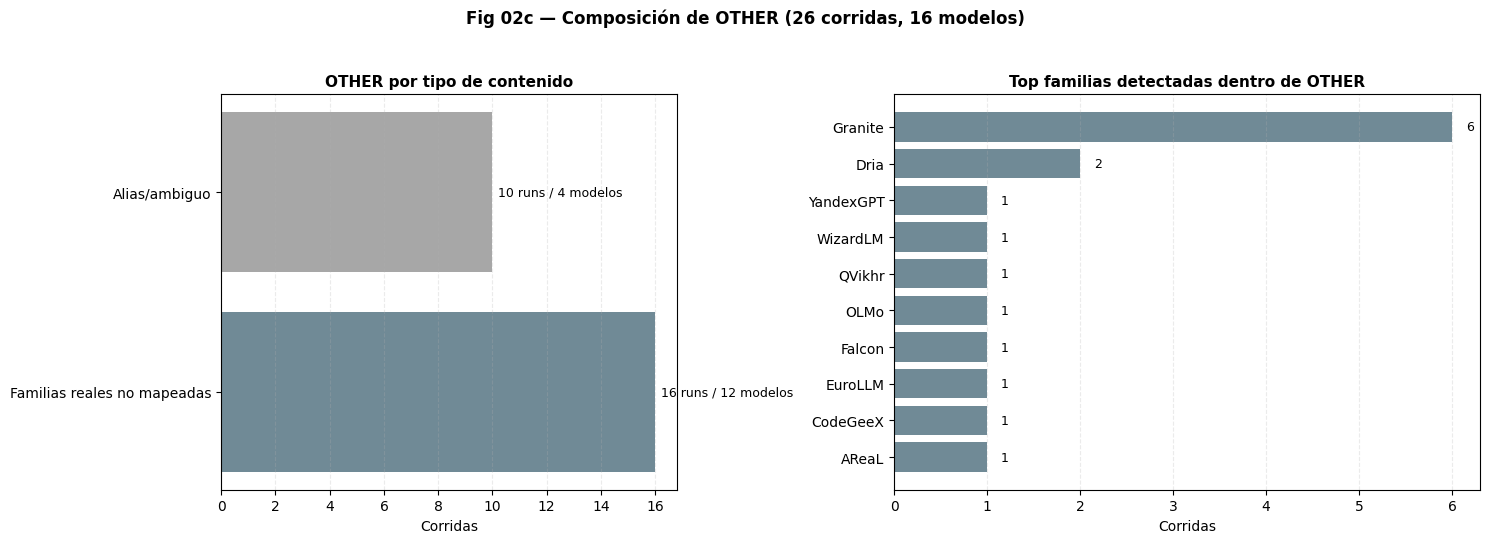

Guardado: ../reports/figures/fig02c_other_composition.png

Detalle OTHER:
                  other_bucket  models  runs
1  Familias reales no mapeadas      12    16
0                Alias/ambiguo       4    10

Familias reales detectadas dentro de OTHER:
  other_real_family  models  runs
5           Granite       3     6
2              Dria       1     2
0             AReaL       1     1
1          CodeGeeX       1     1
3           EuroLLM       1     1
4            Falcon       1     1
6              OLMo       1     1
7            QVikhr       1     1
8          WizardLM       1     1
9         YandexGPT       1     1


In [ ]:
# =====================================
# Fig 02c — Composición de OTHER (familias reales vs alias/ambiguo vs ruido)
# =====================================
# Reutiliza models_clean construido en la celda anterior.

if "models_clean" not in globals():
    models_clean = build_models_agg(df)

other_df = models_clean[models_clean["model_family"] == "OTHER"].copy()

# Detectar familias reales dentro de OTHER por keywords
REAL_FAMILY_MAP = {
    "Granite": ["granite"],
    "Falcon": ["falcon"],
    "EuroLLM": ["eurollm"],
    "YandexGPT": ["yandexgpt"],
    "QVikhr": ["qvikhr"],
    "Dria": ["dria"],
    "WizardLM": ["wizard"],
    "CodeGeeX": ["codegeex"],
    "AReaL": ["areal"],
    "OLMo": ["olmo"],
}

NOISE_NAMES = {
    ".", "..", "active", "hub", "Models", "Dir", "Model Hf", "Local_Pretrained_Model"
}

def detect_real_family(name: str):
    n = str(name).lower()
    for fam, kws in REAL_FAMILY_MAP.items():
        if any(kw in n for kw in kws):
            return fam
    return None

def classify_other_row(name: str):
    n = str(name).strip()
    n_low = n.lower()

    if n in NOISE_NAMES or ("llm_models" in n_low) or (len(n) <= 2):
        return "Ruido/errores", None

    real_fam = detect_real_family(n)
    if real_fam is not None:
        return "Familias reales no mapeadas", real_fam

    return "Alias/ambiguo", None

if other_df.empty:
    print("No hay modelos en OTHER después de la limpieza.")
else:
    cls = other_df["model_name"].apply(classify_other_row)
    other_df["other_bucket"] = cls.apply(lambda x: x[0])
    other_df["other_real_family"] = cls.apply(lambda x: x[1])

    # Panel A: composición por bucket
    comp = (
        other_df.groupby("other_bucket")
                .agg(models=("model_name", "count"), runs=("n_runs", "sum"))
                .reset_index()
    )

    bucket_order = ["Familias reales no mapeadas", "Alias/ambiguo", "Ruido/errores"]
    comp["other_bucket"] = pd.Categorical(comp["other_bucket"], categories=bucket_order, ordered=True)
    comp = comp.sort_values("other_bucket")

    # Panel B: top familias reales dentro de OTHER
    real_fam = (
        other_df[other_df["other_real_family"].notna()]
        .groupby("other_real_family")
        .agg(models=("model_name", "count"), runs=("n_runs", "sum"))
        .reset_index()
        .sort_values("runs", ascending=False)
    )

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.05, 1.35]})

    # A) Barras de buckets
    color_map = {
        "Familias reales no mapeadas": "#607D8B",
        "Alias/ambiguo": "#9E9E9E",
        "Ruido/errores": "#BDBDBD",
    }
    axes[0].barh(
        comp["other_bucket"].astype(str),
        comp["runs"],
        color=[color_map.get(x, "#9E9E9E") for x in comp["other_bucket"].astype(str)],
        alpha=0.9,
    )
    for y, (_, row) in enumerate(comp.iterrows()):
        axes[0].text(row["runs"] + 0.2, y, f"{int(row['runs'])} runs / {int(row['models'])} modelos", va="center", fontsize=9)
    axes[0].set_title("OTHER por tipo de contenido", fontsize=11, fontweight="bold")
    axes[0].set_xlabel("Corridas")
    axes[0].grid(axis="x", linestyle="--", alpha=0.25)

    # B) Top familias reales dentro de OTHER
    if real_fam.empty:
        axes[1].text(0.5, 0.5, "Sin familias reales detectadas\nen OTHER", ha="center", va="center", fontsize=11)
        axes[1].set_axis_off()
    else:
        top_rf = real_fam.head(10).sort_values("runs", ascending=True)
        axes[1].barh(top_rf["other_real_family"], top_rf["runs"], color="#607D8B", alpha=0.9)
        for y, (_, row) in enumerate(top_rf.iterrows()):
            axes[1].text(row["runs"] + 0.15, y, f"{int(row['runs'])}", va="center", fontsize=9)
        axes[1].set_title("Top familias detectadas dentro de OTHER", fontsize=11, fontweight="bold")
        axes[1].set_xlabel("Corridas")
        axes[1].grid(axis="x", linestyle="--", alpha=0.25)

    total_other_runs = int(other_df["n_runs"].sum())
    total_other_models = int(len(other_df))
    fig.suptitle(
        f"Fig 02c — Composición de OTHER ({total_other_runs} corridas, {total_other_models} modelos)",
        fontsize=12,
        fontweight="bold",
    )
    plt.tight_layout(rect=[0, 0, 1, 0.95])

    fig_path_c = FIG_DIR / "fig02c_other_composition.png"
    plt.savefig(fig_path_c, dpi=150, bbox_inches="tight")
    plt.show()

    print("Guardado:", fig_path_c)
    print("\nDetalle OTHER:")
    print(comp)
    if not real_fam.empty:
        print("\nFamilias reales detectadas dentro de OTHER:")
        print(real_fam)

